## Lab 7 
**Naïve Bayes and Decision Trees: Reproducible Pipelines, Evaluation, and Operational Tradeoffs**


## Learning Objectives
By the end of this lab, you will be able to:
1. Implement reproducible ML experiments using fixed seeds, deterministic splits, and clear configuration.
2. Validate input data using schema checks, missing-value audits, and label sanity checks.
3. Train and evaluate a Decision Tree classifier on mixed-type tabular data using a preprocessing pipeline.
4. Regularize and compare Decision Trees using pre-pruning and cost-complexity post-pruning.
5. Implement Naïve Bayes from first principles for a small categorical dataset and diagnose zero-frequency failures.
6. Apply Laplace smoothing and interpret how it changes posterior scores and robustness.
7. Build a text classification pipeline with CountVectorizer + MultinomialNB and compare evaluation metrics.
8. Interpret model behavior and discuss system implications (latency, memory, drift/prior shift, monitoring).

## Tasks
- Set up a reproducible experiment configuration.
- Load two real datasets (tabular credit risk; SMS spam text) and document metadata.
- Implement schema validation checks and identify leakage points.
- Train a baseline Decision Tree pipeline and evaluate with a confusion matrix.
- Improve the Decision Tree via tuning and cost-complexity pruning; visualize tradeoffs.
- Implement Naïve Bayes by hand on a categorical toy dataset.
- Add Laplace smoothing; compare probabilities and discuss failure modes.
- Train a MultinomialNB text classifier; evaluate and interpret errors.
- Conduct error analysis and propose monitoring signals.

## References 
- scikit-learn `fetch_openml`: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.fetch_openml.html
- scikit-learn `train_test_split`: https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- scikit-learn `Pipeline`: https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html
- scikit-learn `ColumnTransformer`: https://scikit-learn.org/stable/modules/generated/sklearn.compose.ColumnTransformer.html
- scikit-learn `DecisionTreeClassifier`: https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html
- scikit-learn `MultinomialNB`: https://scikit-learn.org/stable/modules/generated/sklearn.naive_bayes.MultinomialNB.html
- UCI SMS Spam Collection: https://archive.ics.uci.edu/ml/datasets/sms+spam+collection
- OpenML credit-g (data_id=31): https://www.openml.org/d/31

## Workflow Overview
1. Setup & reproducibility
2. Data acquisition (tabular credit risk)
3. Data validation & leakage review (tabular)
4. Baseline Decision Tree pipeline
5. Evaluation & diagnostics (confusion matrix; error inspection)
6. Optimization (pre-pruning + cost-complexity pruning)
7. Naïve Bayes from first principles (categorical toy example)
8. Text Naïve Bayes system (SMS spam)
9. Systems discussion & reporting


**Note:** In this programming lab, you are required to execute all cells step by step and focus on understanding the methodology and the outcomes at each step. Answering the questions included in this lab (pre-coding and post-execution interpretation questions) is optional and is not required for the completion of the programming lab.

## Step 1 — Setup & Reproducibility

### Pre-coding questions 
1) If you run the same notebook twice but change `random_state`, which outputs should change and which should not? Justify.     
The train/test split and any other randomized results should differ. The data loading, column names, and deterministic calculations should be identical. Changing the seed will affect the randomization of the data splitting.


2) Why might “reproducible splits” still fail to produce reproducible results across machines?  
Different Python, library, or operating system versions can produce different results. Hardware and numerical libraries can also affect calculations.



### Function/class selection + parameter exploration
- Use: `numpy.random.default_rng`, `sklearn.model_selection.train_test_split`  
- Explore `train_test_split` parameters: `test_size`, `stratify`, `random_state`, `shuffle`. Explain impacts on reproducibility and evaluation validity.



**Think like an ML Systems engineer:** 

What exactly would you log in an experiment tracker (data IDs/hashes, preprocessing params, model params, metrics, versions)? Provide at least 5 items.     
Dataset ID or hash, train/test split settings, preprocessing parameters, model parameters, evaluation metrics


In [2]:
# Step 1: Setup & reproducibility
import sys
import platform
import numpy as np
import pandas as pd

RANDOM_STATE = 42
rng = np.random.default_rng(RANDOM_STATE)

print("Python:", sys.version)
print("Platform:", platform.platform())

import sklearn
print("scikit-learn:", sklearn.__version__)


Python: 3.13.9 | packaged by Anaconda, Inc. | (main, Oct 21 2025, 19:09:58) [MSC v.1929 64 bit (AMD64)]
Platform: Windows-11-10.0.26200-SP0
scikit-learn: 1.9.1


### Post-execution interpretation questions
1) What part of the environment information above is most likely to explain “same code, different results”?     
The Python, scikit-learn, NumPy, and operating system versions are the most likely causes.


2) If you were auditing a production model, which versions would you require? Why?      
I would record the Python version, operating system, scikit-learn version, NumPy version, pandas version, and model version. This makes it easier to reproduce the model and investigate differences.


## Step 2 — Data Acquisition (Tabular): OpenML credit-g

### Dataset metadata
- **Name:** credit-g (German credit), OpenML `data_id=31`  
- **Task:** binary classification (good/bad credit risk)  
- **Primary access:** `fetch_openml`  
- **Fallback:** `sklearn.datasets.load_breast_cancer()` (offline)



### Pre-coding questions
1) Why is a Decision Tree a plausible baseline for regulated decisioning systems?       
Decision Trees are easy to understand and explain. Their decision rules can also be inspected by a human as well.


2) What failure mode do you expect if you one-hot encode a high-cardinality categorical feature?    
It can create a very large number of features, increasing memory use, training time, and the risk of overfitting.



### Function/class selection + parameter exploration
- Use: `sklearn.datasets.fetch_openml`  
- Explore: `as_frame`, `return_X_y` and discuss memory/reproducibility implications.


In [3]:
from sklearn.datasets import fetch_openml

# NOTE: Requires internet access to OpenML.
# If this fails in your environment, use the fallback dataset in the next cell.

try:
    credit = fetch_openml(data_id=31, as_frame=True)  # credit-g on OpenML
    df_credit = credit.frame
    print(df_credit.shape)
    display(df_credit.head())
    print("Target column guess:", credit.target_names)
except Exception as e:
    print("OpenML fetch failed:", repr(e))
    df_credit = None


(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,...,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,...,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,...,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,...,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,...,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,...,no known property,53,none,for free,2,skilled,2,none,yes,bad


Target column guess: ['class']


In [4]:
# Fallback (no network): built-in dataset
from sklearn.datasets import load_breast_cancer

if df_credit is None:
    data = load_breast_cancer(as_frame=True)
    df_credit = data.frame
    # Make naming consistent with later code
    df_credit = df_credit.rename(columns={"target": "class"})
    df_credit["class"] = df_credit["class"].map({0: "bad", 1: "good"})
    print("Using fallback dataset:", df_credit.shape)
    display(df_credit.head())


### Post-execution interpretation questions
1) What is the target label distribution? Predict whether stratification is needed.     
The target contains both good and bad credit classes. Stratification is useful so the training and test sets keep a similar class distribution.


2) Which columns are likely categorical? How would you confirm without guessing?    
I would check the column data types and the number of unique values using .dtypes and .nunique(). I would also inspect sample values.


## Step 3 — Data Validation & Leakage Review

### Pre-coding questions
1) Where could leakage occur in a credit-risk dataset pipeline? Give two concrete examples.     
One example is using information that was recorded after the credit decision was made. Another is fitting an imputer or encoder on the entire dataset before splitting it.
   


2) If missing values exist, why might “drop rows with NA” be risky operationally?   
It could remove too many records and may not work well when missing data appears in production. Important cases could be lost.



### Function/class selection + parameter exploration
- Use: pandas `.isna()`, `.dtypes`, `.nunique()`, `.value_counts()`  
- Later: `OneHotEncoder(handle_unknown=...)`. Explore `handle_unknown` and explain production implications.


In [5]:
# Step 3: Data validation

def basic_schema_report(df: pd.DataFrame, target_col: str, max_levels: int = 20) -> pd.DataFrame:
    """Return a compact schema report suitable for quick validation."""
    report = []
    for col in df.columns:
        nunique = df[col].nunique(dropna=True)
        missing = df[col].isna().mean()
        dtype = str(df[col].dtype)
        sample_vals = None
        if nunique <= max_levels:
            sample_vals = df[col].dropna().unique()[:max_levels]
            sample_vals = ", ".join(map(str, sample_vals))
        report.append({
            "column": col,
            "dtype": dtype,
            "missing_rate": missing,
            "n_unique": nunique,
            "sample_values": sample_vals
        })
    rep = pd.DataFrame(report).sort_values(["missing_rate", "n_unique"], ascending=False)

    assert target_col in df.columns, f"Missing target column: {target_col}"
    assert df[target_col].notna().any(), "Target column is all missing."

    n_classes = df[target_col].dropna().nunique()
    assert n_classes >= 2, f"Need >=2 classes, found {n_classes}"

    return rep

TARGET_COL = "class" if "class" in df_credit.columns else (credit.target_names[0] if "credit" in globals() and hasattr(credit, "target_names") else "class")

schema = basic_schema_report(df_credit, target_col=TARGET_COL)
display(schema.head(15))

print("Target distribution:\n", df_credit[TARGET_COL].value_counts(dropna=False))


,column,dtype,missing_rate,n_unique,sample_values
4,credit_amount,int64,0.0,921,None
12,age,int64,0.0,53,None
1,duration,int64,0.0,33,None
3,purpose,category,0.0,10,"radio/tv, education, furniture/equipment, new ..."
2,credit_history,category,0.0,5,"critical/other existing credit, existing paid,..."
5,savings_status,category,0.0,5,"no known savings, <100, 500<=X<1000, >=1000, 1..."
6,employment,category,0.0,5,">=7, 1<=X<4, 4<=X<7, unemployed, <1"
0,checking_status,category,0.0,4,"<0, 0<=X<200, no checking, >=200"
7,installment_commitment,int64,0.0,4,"4, 2, 3, 1"
8,personal_status,category,0.0,4,"male single, female div/dep/mar, male div/sep,..."


Target distribution:
 class
good    700
bad     300
Name: count, dtype: int64


**Think like an ML Systems engineer:** 

If you deploy a one-hot encoder, what happens when a new category appears in production? Which parameter controls this, and what is a safe default?     
An unknown category can cause an error unless it is handled. handle_unknown="ignore" is a safe default because the pipeline can continue when new categories appear.



### Post-execution interpretation questions
1) Which features have the highest missing rate? What would you do first: impute, drop, or add missing indicators? Justify.     
I would first check how much data is missing and whether the missingness has meaning. For a small amount of missing data, imputation is usually the simplest option. Missing indicators could be useful if missingness itself is informative.


2) If the target classes are imbalanced, which metric would you add beyond accuracy?        
I would add precision, recall, F1-score, and possibly ROC-AUC. Recall is especially important when missing a particular class is costly.


## Step 4 — Baseline Decision Tree Pipeline (Tabular)

### Pre-coding questions
1) Predict: Will an unconstrained tree likely overfit? What metric pattern would confirm it?    
Yes. I would expect very high training accuracy but noticeably lower test accuracy.


2) What tradeoff exists between interpretability (shallow tree) and accuracy (deeper tree)?     
A shallow tree is easier to understand but may have lower accuracy. A deeper tree can capture more patterns but is harder to interpret and may overfit.



### Function/class selection + parameter exploration
- Use: `train_test_split`, `Pipeline`, `ColumnTransformer`, `OneHotEncoder`, `SimpleImputer`, `DecisionTreeClassifier`
- Explore DecisionTree params: `criterion`, `max_depth`, `min_samples_leaf`, `class_weight`, `random_state`.


              precision    recall  f1-score   support

         bad       0.42      0.43      0.43        60
        good       0.75      0.74      0.75       140

    accuracy                           0.65       200
   macro avg       0.59      0.59      0.59       200
weighted avg       0.65      0.65      0.65       200



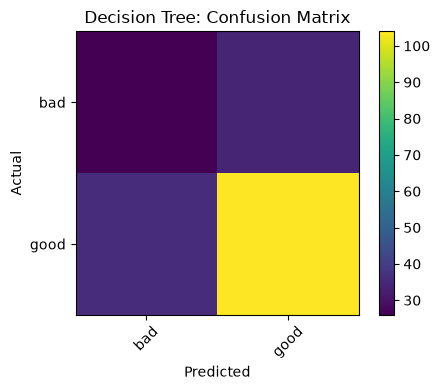

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import confusion_matrix, classification_report
import matplotlib.pyplot as plt

# Split
X = df_credit.drop(columns=[TARGET_COL])
y = df_credit[TARGET_COL].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y
)

# Identify column types (robust to object/category/string dtypes)
num_cols = [c for c in X_train.columns if pd.api.types.is_numeric_dtype(X_train[c])]
cat_cols = [c for c in X_train.columns if c not in num_cols]

numeric_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer(
    transformers=[
        ("num", numeric_pipe, num_cols),
        ("cat", categorical_pipe, cat_cols)
    ]
)

dt = DecisionTreeClassifier(random_state=RANDOM_STATE)

model_dt = Pipeline(steps=[
    ("prep", preprocess),
    ("model", dt)
])

model_dt.fit(X_train, y_train)
y_pred = model_dt.predict(X_test)

print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred, labels=sorted(y.unique()))
plt.figure(figsize=(5, 4))
plt.imshow(cm)
plt.title("Decision Tree: Confusion Matrix")
plt.xticks(range(len(sorted(y.unique()))), sorted(y.unique()), rotation=45)
plt.yticks(range(len(sorted(y.unique()))), sorted(y.unique()))
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.tight_layout()
plt.show()

### Post-execution interpretation questions
1) Which class is harder to predict? Support your answer using the confusion matrix.  
The class with more incorrect predictions and a lower recall is harder to predict. The confusion matrix shows how often each class is being misclassified.


2) If false negatives are more costly than false positives, which metric(s) matter most?    
Recall is especially important because it measures how many actual positive cases are correctly identified. I would also look at the confusion matrix and possibly F1-score.


3) What is one reason the confusion matrix can look “good” but still be misleading in production?   
The test data may not represent the actual production population. Class distributions and error costs can change after deployment.


## Step 5 — Diagnostics: Explainability and Error Inspection 

### Pre-coding questions
1) If compliance requires “meaningful information” for decisions, what is the minimal explanation artifact you would store per prediction?      
I would store the prediction, model version, timestamp, input information used for the decision, and the main decision path or contributing features.


2) Why can feature importance from trees be misleading with correlated features?        
Correlated features can contain similar information, so the tree may give most of the importance to one feature even though the other feature is also useful.



### Function/class selection + parameter exploration
- Use: `sklearn.tree.export_text`  
- Explore: `get_depth()`, `get_n_leaves()`.



**Think like an ML Systems engineer:** 

If you log explanations, what is the privacy risk? Propose one mitigation.      
Explanations could expose sensitive customer information. I would limit what is stored, remove unnecessary personal information, and restrict access to explanation logs.


In [7]:
from sklearn.tree import export_text

fitted_tree = model_dt.named_steps["model"]
print("Tree depth:", fitted_tree.get_depth())
print("Num leaves:", fitted_tree.get_n_leaves())

# Feature names after preprocessing
onehot = model_dt.named_steps["prep"].named_transformers_["cat"].named_steps["onehot"]
num_feature_names = num_cols
cat_feature_names = list(onehot.get_feature_names_out(cat_cols))
all_feature_names = num_feature_names + cat_feature_names

print(export_text(fitted_tree, feature_names=all_feature_names, max_depth=3))


Tree depth: 19
Num leaves: 160
|--- checking_status_no checking <= 0.50
|   |--- duration <= 11.50
|   |   |--- property_magnitude_real estate <= 0.50
|   |   |   |--- credit_history_critical/other existing credit <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- credit_history_critical/other existing credit >  0.50
|   |   |   |   |--- truncated branch of depth 2
|   |   |--- property_magnitude_real estate >  0.50
|   |   |   |--- job_high qualif/self emp/mgmt <= 0.50
|   |   |   |   |--- truncated branch of depth 5
|   |   |   |--- job_high qualif/self emp/mgmt >  0.50
|   |   |   |   |--- class: bad
|   |--- duration >  11.50
|   |   |--- duration <= 47.50
|   |   |   |--- credit_amount <= 1381.50
|   |   |   |   |--- truncated branch of depth 13
|   |   |   |--- credit_amount >  1381.50
|   |   |   |   |--- truncated branch of depth 16
|   |   |--- duration >  47.50
|   |   |   |--- savings_status_no known savings <= 0.50
|   |   |   |   |--- truncated branc

### Post-execution interpretation questions
1) Is the tree “too large” for a human reviewer? What threshold would you set for depth/leaves in a regulated workflow?     
If the tree has many levels and leaves, it becomes difficult to review. I would prefer a shallow tree, such as a depth around 4–6, and limit the number of leaves based on the review requirements.


2) What operational cost changes if you increase tree depth (training vs inference)?        
Training generally becomes more complex and the model uses more memory. Inference also requires following more decision rules, although tree predictions are usually still relatively fast.


## Step 6 — Optimization: Pre-pruning and Cost-Complexity Pruning 

### Pre-coding questions
1) Predict the effect of increasing `min_samples_leaf` on variance and bias.    
Increasing min_samples_leaf usually decreases variance and overfitting, but it can increase bias.


2) Why might cost-complexity pruning be preferable to manually setting `max_depth`?     
Cost-complexity pruning considers the overall complexity of the tree and can remove branches that do not provide enough improvement.


3) Why might cost-complexity pruning be preferable to manually setting `max_depth`?     
It provides a more systematic way to balance tree complexity and performance instead of choosing only one depth value.



### Function/class selection + parameter exploration
- Use: `DecisionTreeClassifier.cost_complexity_pruning_path`, `ccp_alpha`  
- Explore: `ccp_alpha`, `max_depth`, `min_samples_leaf`, `criterion`.



**Think like an ML Systems engineer:**

The sweep below uses the test set to pick `ccp_alpha`. Why is that risky? What would you do instead?        
It is risky because the test set is being used to tune the model, so the final test score is no longer an unbiased estimate. I would choose the alpha using cross-validation on the training data and use the test set only for final evaluation.


Accuracy (unconstrained): 0.65
Accuracy (pre-pruned): 0.71


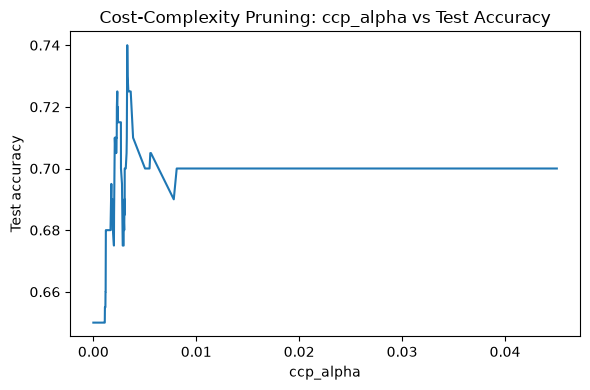

Best alpha (by test accuracy in this sweep): 0.0032957130592349976
Accuracy (ccp-pruned): 0.74
Depth (ccp-pruned): 8
Leaves (ccp-pruned): 18


In [8]:
from sklearn.metrics import accuracy_score

# Fit a pre-pruned tree (simple baseline improvement)
dt_pruned = DecisionTreeClassifier(
    random_state=RANDOM_STATE,
    max_depth=5,
    min_samples_leaf=10
)

model_dt_pruned = Pipeline(steps=[
    ("prep", preprocess),
    ("model", dt_pruned)
])
model_dt_pruned.fit(X_train, y_train)

pred_base = model_dt.predict(X_test)
pred_preprune = model_dt_pruned.predict(X_test)

print("Accuracy (unconstrained):", accuracy_score(y_test, pred_base))
print("Accuracy (pre-pruned):", accuracy_score(y_test, pred_preprune))

# Cost-complexity pruning path on the *preprocessed* training matrix
X_train_mat = preprocess.fit_transform(X_train)
X_test_mat = preprocess.transform(X_test)

dt_for_path = DecisionTreeClassifier(random_state=RANDOM_STATE)
dt_for_path.fit(X_train_mat, y_train)

path = dt_for_path.cost_complexity_pruning_path(X_train_mat, y_train)
ccp_alphas = path.ccp_alphas

# Train a sequence of pruned trees
accs = []
for a in ccp_alphas:
    clf = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=a)
    clf.fit(X_train_mat, y_train)
    accs.append(accuracy_score(y_test, clf.predict(X_test_mat)))

plt.figure(figsize=(6, 4))
plt.plot(ccp_alphas, accs)
plt.title("Cost-Complexity Pruning: ccp_alpha vs Test Accuracy")
plt.xlabel("ccp_alpha")
plt.ylabel("Test accuracy")
plt.tight_layout()
plt.show()

best_idx = int(np.argmax(accs))
best_alpha = float(ccp_alphas[best_idx])
print("Best alpha (by test accuracy in this sweep):", best_alpha)

dt_ccp = DecisionTreeClassifier(random_state=RANDOM_STATE, ccp_alpha=best_alpha)
dt_ccp.fit(X_train_mat, y_train)

print("Accuracy (ccp-pruned):", accuracy_score(y_test, dt_ccp.predict(X_test_mat)))
print("Depth (ccp-pruned):", dt_ccp.get_depth())
print("Leaves (ccp-pruned):", dt_ccp.get_n_leaves())

### Post-execution interpretation questions
1) Did pruning reduce model size (depth/leaves)? Did accuracy improve or degrade? Interpret tradeoffs.      
Pruning should reduce the tree depth and number of leaves. Accuracy may improve slightly or decrease, but a smaller tree can generalize better and be easier to explain.


2) If accuracy is flat across many alphas, what should decide your choice?      
I would choose the simpler tree because it is easier to explain, maintain, and monitor.


3) What is a monitoring signal that might indicate the need to retrain a credit-risk tree?      
A drop in validation performance or a significant change in the distribution of input features or target classes could indicate that retraining is needed.
   


## Step 7 — Naïve Bayes from First Principles

### Pre-coding questions
1) Why does Naïve Bayes multiply many probabilities, and why does that cause numerical issues?      
Naïve Bayes multiplies the conditional probabilities of the features to calculate the posterior score. Multiplying many small probabilities can produce extremely small numbers and numerical underflow.
   


2) What failure mode occurs when any conditional probability is zero? Predict the effect on the posterior score.        
The entire product becomes zero, so that class can receive a posterior score of zero even if the other features support it.



### Function/class selection + parameter exploration
- Use: pandas `crosstab`, numpy `log`.


In [9]:
# Toy dataset: Enrolls ~ Age + Income + Jobsatisfaction + Desire
toy = pd.DataFrame([
    {"Age": "<=30", "Income": "High",   "Jobsatisfaction": "No",  "Desire": "Fair", "Enrolls": "No"},
    {"Age": "<=30", "Income": "High",   "Jobsatisfaction": "No",  "Desire": "Excellent", "Enrolls": "No"},
    {"Age": "31-40","Income": "High",   "Jobsatisfaction": "No",  "Desire": "Fair", "Enrolls": "Yes"},
    {"Age": ">40",  "Income": "Medium", "Jobsatisfaction": "No",  "Desire": "Fair", "Enrolls": "Yes"},
    {"Age": ">40",  "Income": "Low",    "Jobsatisfaction": "Yes", "Desire": "Fair", "Enrolls": "Yes"},
    {"Age": ">40",  "Income": "Low",    "Jobsatisfaction": "Yes", "Desire": "Excellent", "Enrolls": "No"},
    {"Age": "31-40","Income": "Low",    "Jobsatisfaction": "Yes", "Desire": "Excellent", "Enrolls": "Yes"},
    {"Age": "<=30", "Income": "Medium", "Jobsatisfaction": "No",  "Desire": "Fair", "Enrolls": "No"},
    {"Age": "<=30", "Income": "Low",    "Jobsatisfaction": "Yes", "Desire": "Fair", "Enrolls": "Yes"},
    {"Age": ">40",  "Income": "Medium", "Jobsatisfaction": "Yes", "Desire": "Fair", "Enrolls": "Yes"},
    {"Age": "<=30", "Income": "Medium", "Jobsatisfaction": "Yes", "Desire": "Excellent", "Enrolls": "Yes"},
    {"Age": "31-40","Income": "Medium", "Jobsatisfaction": "No",  "Desire": "Excellent", "Enrolls": "Yes"},
    {"Age": "31-40","Income": "High",   "Jobsatisfaction": "Yes", "Desire": "Fair", "Enrolls": "Yes"},
    {"Age": ">40",  "Income": "Medium", "Jobsatisfaction": "No",  "Desire": "Excellent", "Enrolls": "No"},
])

# Train/test split (last row is test)
train_toy = toy.iloc[:-1].copy()
test_toy = toy.iloc[[-1]].copy()

print("Train size:", train_toy.shape)
print("Test row:\n", test_toy)

# Priors
priors = train_toy["Enrolls"].value_counts(normalize=True)
print("Priors:\n", priors)

features = ["Age", "Income", "Jobsatisfaction", "Desire"]

# Conditional probability tables P(feature=value | class)
cond_tables = {}
for f in features:
    tab = pd.crosstab(train_toy["Enrolls"], train_toy[f], normalize="index")
    cond_tables[f] = tab
    print("\nConditional for", f)
    display(tab)

# Score the test instance using log-space
x = test_toy.iloc[0]

classes = priors.index.tolist()
log_scores = {}
for c in classes:
    s = np.log(priors.loc[c])
    for f in features:
        s += np.log(cond_tables[f].loc[c, x[f]])
    log_scores[c] = s

print("\nLog-scores:", log_scores)
print("Predicted class:", max(log_scores, key=log_scores.get))

Train size: (13, 5)
Test row:
     Age  Income Jobsatisfaction     Desire Enrolls
13  >40  Medium              No  Excellent      No
Priors:
 Enrolls
Yes    0.692308
No     0.307692
Name: proportion, dtype: float64

Conditional for Age


Age,31-40,<=30,>40
Enrolls,,,
No,0.000000,0.750000,0.250000
Yes,0.444444,0.222222,0.333333



Conditional for Income


Income,High,Low,Medium
Enrolls,,,
No,0.500000,0.250000,0.250000
Yes,0.222222,0.333333,0.444444



Conditional for Jobsatisfaction


Jobsatisfaction,No,Yes
Enrolls,,
No,0.750000,0.250000
Yes,0.333333,0.666667



Conditional for Desire


Desire,Excellent,Fair
Enrolls,,
No,0.500000,0.500000
Yes,0.333333,0.666667



Log-scores: {'Yes': np.float64(-4.4744918623459755), 'No': np.float64(-4.932072971593153)}
Predicted class: Yes


### Post-execution interpretation questions
1) Which single feature value contributed the most to the decision? How would you quantify contribution in log-space?       
The feature with the largest absolute contribution to the log-score difference contributed the most. I would compare its log(P(feature | class)) value between the classes.


2) What breaks if any `P(x_f | c)` is zero?         
The log of zero is undefined, so the log-score effectively becomes negative infinity and that class is eliminated.

 
3) Why is log-space scoring a systems-reliability improvement?      
It avoids multiplying many tiny probabilities together, which reduces numerical underflow and makes the calculation more stable.


## Step 8 — Laplace Smoothing 

### Pre-coding questions
1) With Laplace smoothing, which probabilities increase most: common or rare/unseen events? Why?    
Rare and unseen events increase the most because smoothing adds a small count to every possible category.


2) What tradeoff does smoothing introduce (bias vs robustness)?     
Smoothing adds some bias because the probabilities are adjusted away from the observed counts, but it makes the model more robust to unseen values.



### Function/class selection + parameter exploration
- Implement smoothing manually and compare to scikit-learn’s `alpha` concept.



**Think like an ML Systems engineer:** 

In a streaming text system, what is the analogous robustness mechanism for unseen tokens?       
The system should handle unknown tokens safely instead of failing. An <UNK> or unknown-token mechanism is one example.


In [10]:
def smoothed_conditional_table(df: pd.DataFrame, target: str, feature: str, alpha: float = 1.0) -> pd.DataFrame:
    """Return P(feature=value | class) with Laplace smoothing."""
    counts = pd.crosstab(df[target], df[feature])
    counts_sm = counts + alpha
    probs = counts_sm.div(counts_sm.sum(axis=1), axis=0)
    return probs

alpha = 1.0
cond_tables_sm = {f: smoothed_conditional_table(train_toy, "Enrolls", f, alpha=alpha) for f in features}

log_scores_sm = {}
for c in classes:
    s = np.log(priors.loc[c])
    for f in features:
        s += np.log(cond_tables_sm[f].loc[c, x[f]])
    log_scores_sm[c] = s

print("Smoothed log-scores (alpha=1.0):", log_scores_sm)
print("Smoothed predicted class:", max(log_scores_sm, key=log_scores_sm.get))

Smoothed log-scores (alpha=1.0): {'Yes': np.float64(-4.365007629504287), 'No': np.float64(-4.7827932220004925)}
Smoothed predicted class: Yes


### Post-execution interpretation questions
1) Did the predicted class change? If not, what changed and why does it matter? —       
Smoothing did not change the final decision. It still changed the probability scores and makes the model less sensitive to zero-frequency events.

 
2) In production, what symptom might indicate you need more smoothing (or a different model)?       
Frequent unseen tokens, unstable predictions, or many zero/near-zero probabilities could indicate that more smoothing or a different model is needed.


## Step 9 — Text Naïve Bayes System: SMS Spam Pipeline

### Dataset metadata
- **Name:** SMS Spam Collection (UCI)
- **Target:** `ham` vs `spam`
- **Primary link:** https://archive.ics.uci.edu/ml/datasets/sms+spam+collection
- **Direct zip:** https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip
- **Fallback mirror:** https://huggingface.co/datasets/ucirvine/sms_spam



### Pre-coding questions
1) Why is MultinomialNB often a strong baseline for sparse text? Discuss runtime scaling in terms of nonzero features.      
MultinomialNB is fast and works well with sparse word-count data. Its calculations mainly involve the nonzero features in each message, so it is efficient for large text datasets.


2) What leakage risk exists if you learn the vocabulary on the full dataset before splitting?       
The test data would influence the vocabulary used by the model. This gives the model information from the test set and can make the evaluation overly optimistic.


3) If spam prevalence changes (prior drift), what metric might degrade first: accuracy, precision, or recall? Justify.      
Precision can degrade quickly because the number of predicted spam messages that are actually spam can change when the spam rate changes. The class prior affects how reliable the predictions are.



### Function/class selection + parameter exploration
- Use: `CountVectorizer`, `MultinomialNB`, `Pipeline`
- Explore CountVectorizer: `min_df`, `ngram_range`, `stop_words` (memory/latency).  
- Explore MultinomialNB: `alpha`, `fit_prior`, `class_prior` (prior drift/robustness).



**Think like an ML Systems engineer:** 

Propose two production monitoring dashboards for spam filtering; list 3+ signals each.      
Model Performance
- Precision
- Recall
- False-positive rate   

Data/Traffic Monitoring
- Spam percentage
- Message volume
- Unknown/new token rate


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


label
ham     4825
spam     747
Name: count, dtype: int64
              precision    recall  f1-score   support

         ham       0.99      1.00      0.99       966
        spam       0.99      0.91      0.94       149

    accuracy                           0.99      1115
   macro avg       0.99      0.95      0.97      1115
weighted avg       0.99      0.99      0.99      1115



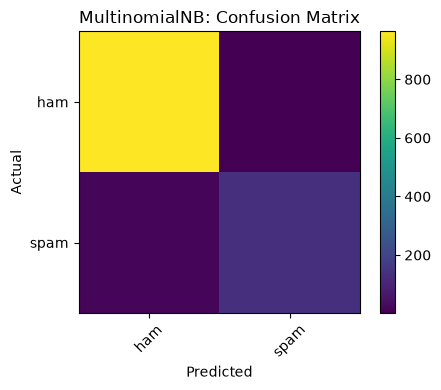

ROC-AUC: 0.9760376283574417

False positives (ham -> spam):


,text,y_true,y_pred
380,K..u also dont msg or reply to his msg..,ham,spam
700,We have sent JD for Customer Service cum Accou...,ham,spam



False negatives (spam -> ham):


,text,y_true,y_pred
44,FreeMsg Hey there darling it's been 3 week's n...,spam,ham
123,Talk sexy!! Make new friends or fall in love i...,spam,ham
196,ringtoneking 84484,spam,ham
219,Sorry I missed your call let's talk when you h...,spam,ham
235,"Latest News! Police station toilet stolen, cop...",spam,ham


In [11]:
import os
import zipfile
import urllib.request
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import roc_auc_score

# Download + load SMS Spam Collection from UCI
uci_zip_url = "https://archive.ics.uci.edu/static/public/228/sms+spam+collection.zip"
out_dir = "data_sms"
os.makedirs(out_dir, exist_ok=True)
zip_path = os.path.join(out_dir, "sms_spam_collection.zip")

try:
    if not os.path.exists(zip_path):
        urllib.request.urlretrieve(uci_zip_url, zip_path)

    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(out_dir)

    data_path = os.path.join(out_dir, "SMSSpamCollection")
    sms = pd.read_csv(data_path, sep="\t", header=None, names=["label", "text"])
    display(sms.head())
    print(sms["label"].value_counts())
except Exception as e:
    print("UCI download/load failed:", repr(e))
    print("Fallback suggestion: use a hosted mirror or a local copy.")
    raise

X_text = sms["text"].astype(str)
y_text = sms["label"].astype(str)

Xtr, Xte, ytr, yte = train_test_split(
    X_text, y_text,
    test_size=0.2,
    random_state=RANDOM_STATE,
    stratify=y_text
)

# Recommended starting params: min_df=2, ngram_range=(1,2)
text_model = Pipeline(steps=[
    ("vect", CountVectorizer(min_df=2, ngram_range=(1, 2))),
    ("nb", MultinomialNB(alpha=1.0))
])

text_model.fit(Xtr, ytr)

pred_label = text_model.predict(Xte)
print(classification_report(yte, pred_label))

labels_sorted = sorted(y_text.unique())
cm2 = confusion_matrix(yte, pred_label, labels=labels_sorted)
plt.figure(figsize=(5, 4))
plt.imshow(cm2)
plt.title("MultinomialNB: Confusion Matrix")
plt.xticks(range(len(labels_sorted)), labels_sorted, rotation=45)
plt.yticks(range(len(labels_sorted)), labels_sorted)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.colorbar()
plt.tight_layout()
plt.show()

# Probabilities for ROC-AUC (binary: choose 'spam' as positive)
proba = text_model.predict_proba(Xte)
spam_col = list(text_model.named_steps["nb"].classes_).index("spam")
spam_score = proba[:, spam_col]

y_true_bin = (yte == "spam").astype(int)
auc = roc_auc_score(y_true_bin, spam_score)
print("ROC-AUC:", auc)

# Simple error analysis
te_df = pd.DataFrame({"text": Xte.values, "y_true": yte.values, "y_pred": pred_label})
fp = te_df[(te_df.y_true == "ham") & (te_df.y_pred == "spam")].head(5)
fn = te_df[(te_df.y_true == "spam") & (te_df.y_pred == "ham")].head(5)

print("\nFalse positives (ham -> spam):")
display(fp)
print("\nFalse negatives (spam -> ham):")
display(fn)

### Post-execution interpretation questions
1) Which error type is more dangerous for an SMS spam filter: FP or FN? Explain in terms of product cost.       
False positives can be more dangerous because a legitimate message could be incorrectly marked as spam and hidden from the user. The exact priority depends on the product's goals.


2) If you increase `ngram_range` to (1,3), what happens to memory and latency? Why?         
The number of features increases because the model now stores unigrams, bigrams, and trigrams. This increases memory usage and can also increase training and prediction time.


3) What is one concrete procedure to detect prior drift in spam prevalence?         
Track the percentage of messages labeled as spam over time and compare it with the historical baseline. A significant sustained change would indicate possible prior drift.


4) What is a limitation of MultinomialNB probabilities with correlated tokens, and how might that affect thresholding?      
MultinomialNB assumes the features are conditionally independent, but words can be correlated. This can make the predicted probabilities poorly calibrated, which can make probability thresholds less reliable.


**End of Lab**